In [50]:
from tsgo.container.sample_polyhedron import cube, triangular_pyramid, h_box, pointy_star

In [51]:
import pickle
import glob
import os

def get_data(root_dir="output/cube", data_key='elapsed_time'):
    """
    Reads pkl files from output/cube/p<i>/euclidean/<subdir>/*.pkl
    and returns a dict of {p_value: elapsed_time}.
    """
    results = {}
    
    # Pattern to match the nested structure: p<i>, then euclidean, then any subdir, then .pkl
    # Adjust the pattern if your 'something_here' is multiple levels deep
    pattern = os.path.join(root_dir, "p*", "euclidean", "*", "*.pkl")
    
    for filepath in glob.glob(pattern):
        try:
            # Extract the 'p' value from the path (e.g., from 'p56' extract 56)
            # Path looks like: output/cube/p56/euclidean/...
            parts = filepath.split(os.sep)
            # Find the p<number> folder in the path
            p_folders = [p for p in parts if p.startswith('p') and p[1:].isdigit()]
            if not p_folders:
                raise ValueError("No valid p<number> folder found in path")
            p_folder = p_folders[0]
            p_value = int(p_folder[1:]) 
            
            with open(filepath, 'rb') as f:
                data = pickle.load(f)
                
            # Store the elapsed time using p as the key, taking min if already exists
            if data_key in data:
                if p_value in results:
                    results[p_value] = min(results[p_value], data[data_key])
                else:
                    results[p_value] = data[data_key]
                
        except (IndexError, ValueError, pickle.UnpicklingError, KeyError) as e:
            print(f"Skipping {filepath}: {e}")
            
    return results

In [52]:
cube_data = get_data(root_dir="../output/cube")
tetrahedron_data = get_data(root_dir="../output/tetrahedron")
h_box_data = get_data(root_dir="../output/h-box")
pointy_star_data = get_data(root_dir="../output/pointy-star")

# remove the cube time fro p=21
if 21 in cube_data:
    del cube_data[21]

In [53]:
import pandas as pd

# Create a DataFrame from the results (the index will be the p values, each container has different p values)
df_cube = pd.DataFrame.from_dict(cube_data, orient='index', columns=['cube_elapsed_time'])
df_tetrahedron = pd.DataFrame.from_dict(tetrahedron_data, orient='index', columns=['tetrahedron_elapsed_time'])
df_h_box = pd.DataFrame.from_dict(h_box_data, orient='index', columns=['h_box_elapsed_time'])
df_pointy_star = pd.DataFrame.from_dict(pointy_star_data, orient='index', columns=['pointy_star_elapsed_time'])

# Merge the DataFrames on the index (p values)
df = df_cube.join(df_tetrahedron, how='outer').join(df_h_box, how='outer').join(df_pointy_star, how='outer')
df

,cube_elapsed_time,tetrahedron_elapsed_time,h_box_elapsed_time,pointy_star_elapsed_time
1,8.440095,2.887406,3.414630,5.753041
2,1.140688,6.081148,4.508160,12.899487
3,1.333511,10.412523,8.599374,19.789046
4,1.379081,9.572183,11.054389,25.427989
5,1.453584,39.414463,23.058528,30.622667
6,28.486050,153.663390,30.820566,58.200384
7,20.431540,22.470337,42.937709,72.414592
8,13.632371,41.900862,265.284824,74.885603
9,40.989757,27.531552,233.110341,127.886238
10,65.874732,40.414561,481.906351,177.446541


In [54]:
# plot the df with x axis as p and y axis as elapsed time, with different lines for each container
import matplotlib.pyplot as plt
cube_times = df['cube_elapsed_time'].dropna()
tetrahedron_times = df['tetrahedron_elapsed_time'].dropna()
h_box_times = df['h_box_elapsed_time'].dropna()
pointy_star_times = df['pointy_star_elapsed_time'].dropna()

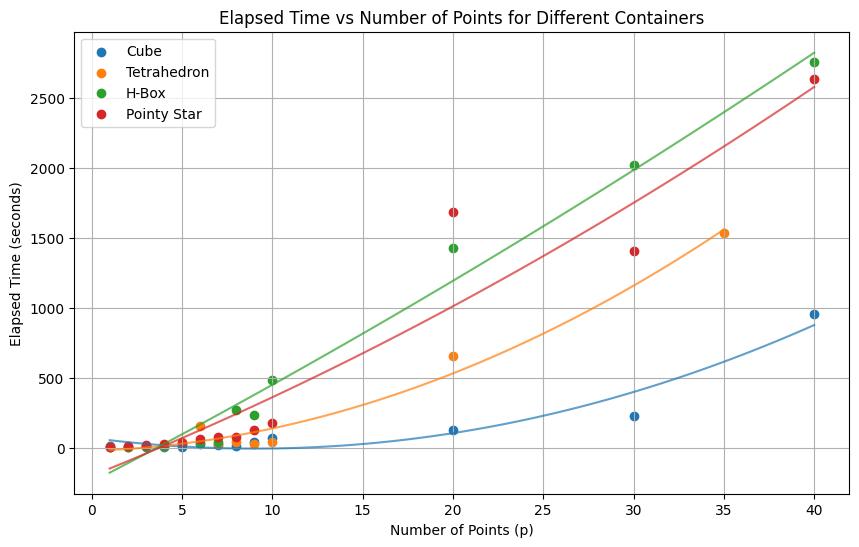

In [55]:
import numpy as np

# plot
plt.figure(figsize=(10, 6))
cube_plot = cube_times[cube_times.index <= 40]
tetra_plot = tetrahedron_times[tetrahedron_times.index <= 40]
h_box_plot = h_box_times[h_box_times.index <= 40]
pointy_plot = pointy_star_times[pointy_star_times.index <= 40]

plt.scatter(cube_plot.index, cube_plot.values, label='Cube', marker='o')
plt.scatter(tetra_plot.index, tetra_plot.values, label='Tetrahedron', marker='o')
plt.scatter(h_box_plot.index, h_box_plot.values, label='H-Box', marker='o')
plt.scatter(pointy_plot.index, pointy_plot.values, label='Pointy Star', marker='o')

# Fit and plot quadratic trend lines

for data, label in [(cube_plot, 'Cube'), (tetra_plot, 'Tetrahedron'), 
                     (h_box_plot, 'H-Box'), (pointy_plot, 'Pointy Star')]:
    coeffs = np.polyfit(data.index, data.values, 2)
    poly = np.poly1d(coeffs)
    x_trend = np.linspace(data.index.min(), data.index.max(), 100)
    plt.plot(x_trend, poly(x_trend), '-', alpha=0.7)

plt.xlabel('Number of Points (p)')
plt.ylabel('Elapsed Time (seconds)')
plt.title('Elapsed Time vs Number of Points for Different Containers')
plt.legend()
plt.grid()
plt.show()